# Immune organisation around the tumour boundary — Visium HD, colorectal cancer

Spatial transcriptomics, from the GEO archives through to the gradient.

**Question**

- In colorectal cancer, are immune cells distributed evenly through the tumour, or organised relative to its edge?
- If there is a gradient, does it hold across patients or is it one section's anatomy?

**Data**

- [GSE280318](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE280318) — Oliveira, Romero, Chung *et al.*, *Nature Genetics* (2025)
- Visium HD, 8 µm bins, human colorectal cancer. Three tumour sections (P1, P2, P5) carry the published per-bin annotation.
- Each section is ~500,000 in-tissue bins.

**Approach**

- Sections are processed independently: own boundary, own distance scale, own composition.
- Pooling happens at the summary level with section as a covariate, never by concatenating bins.
- A gradient has to replicate in direction across at least 2 of 3 sections to be reported.

Five points are marked **Decision**.

---

## 0. Setup

Run `bash 00_download_data.sh` first. It pulls ~150 MB from GEO.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
from scipy import stats

for cat in (FutureWarning, DeprecationWarning, UserWarning, RuntimeWarning):
    warnings.simplefilter("ignore", category=cat)

SEED = 0
np.random.seed(SEED)

DATA = Path("data")
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

sns.set_style("ticks")
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 200, "font.size": 9})

BIN_UM = 8.0          # Visium HD bin pitch, from the assay
sections = pd.read_csv(DATA / "section_manifest.csv")
sections

,section,metadata,counts
0,P1CRC,P1CRC_Metadata.parquet,GSM8594567_P1CRC_filtered_feature_bc_matrix.h5
1,P2CRC,P2CRC_Metadata.parquet,NaN
2,P5CRC,P5CRC_Metadata.parquet,NaN


## 1. Loading, and working out what the coordinates mean

The metadata parquet carries one row per bin: coordinates, the published
cell-type calls, and the tumour/non-tumour assignment.

> ### Decision 1 — calibrate the coordinate scale, do not assume it
>
> - `X` and `Y` are continuous and unitless in the file. Distances reported in those units mean nothing to a reader.
> - The bins sit on a regular lattice with a known pitch of 8 µm, so the scale can be measured rather than guessed: take the nearest-neighbour distance between bins and set it equal to 8 µm.
> - Doing this per section also catches a section that was exported on a different scale.

In [2]:
KEEP = ["barcode", "tissue", "X", "Y", "UnsupervisedL1", "DeconvolutionLabel1", "Periphery"]

def load_section(path: Path) -> pd.DataFrame:
    df = pq.read_table(path, columns=KEEP).to_pandas()
    df = df[df["tissue"].astype(str) == "1"].reset_index(drop=True)
    return df


def um_per_unit(xy: np.ndarray, n_probe: int = 20000, seed: int = SEED) -> float:
    # nearest-neighbour spacing on the bin lattice == one 8 um bin
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(xy), min(n_probe, len(xy)), replace=False)
    d, _ = cKDTree(xy).query(xy[idx], k=2)
    return BIN_UM / np.median(d[:, 1])


secs, scales = {}, {}
for r in sections.itertuples():
    df = load_section(DATA / r.metadata)
    xy = df[["X", "Y"]].to_numpy(float)
    scales[r.section] = um_per_unit(xy)
    df["x_um"] = xy[:, 0] * scales[r.section]
    df["y_um"] = xy[:, 1] * scales[r.section]
    secs[r.section] = df

pd.DataFrame({
    "bins": {k: len(v) for k, v in secs.items()},
    "um per unit": {k: round(v, 2) for k, v in scales.items()},
    "width (mm)": {k: round(np.ptp(v["x_um"]) / 1000, 2) for k, v in secs.items()},
    "height (mm)": {k: round(np.ptp(v["y_um"]) / 1000, 2) for k, v in secs.items()},
})

,bins,um per unit,width (mm),height (mm)
P1CRC,507684,32.45,6.54,6.71
P2CRC,545913,34.35,6.75,6.74
P5CRC,541968,33.26,6.69,6.72


The capture area comes out at ~6.5 mm per side in every section, which is the
Visium HD slide geometry. The calibration is consistent.

In [3]:
lvl = (pd.concat([v["UnsupervisedL1"].value_counts(normalize=True).rename(k) for k, v in secs.items()], axis=1)
       .fillna(0).mul(100).round(1).sort_values(list(secs)[0], ascending=False))
lvl.columns.name = "fraction of bins (%)"
lvl

fraction of bins (%),P1CRC,P2CRC,P5CRC
UnsupervisedL1,,,
Unknown,25.4,15.5,17.3
Tumor,22.5,38.2,17.6
Intestinal Epithelial,10.9,7.7,15.7
Fibroblast,10.4,12.3,8.6
T cells,8.6,2.1,3.8
B cells,7.9,6.6,9.0
Smooth Muscle,5.4,6.8,17.9
Endothelial,4.4,4.1,5.2
Myeloid,4.3,6.7,4.3


## 2. The sections

Tumour, stroma and immune bins, plotted in physical units.

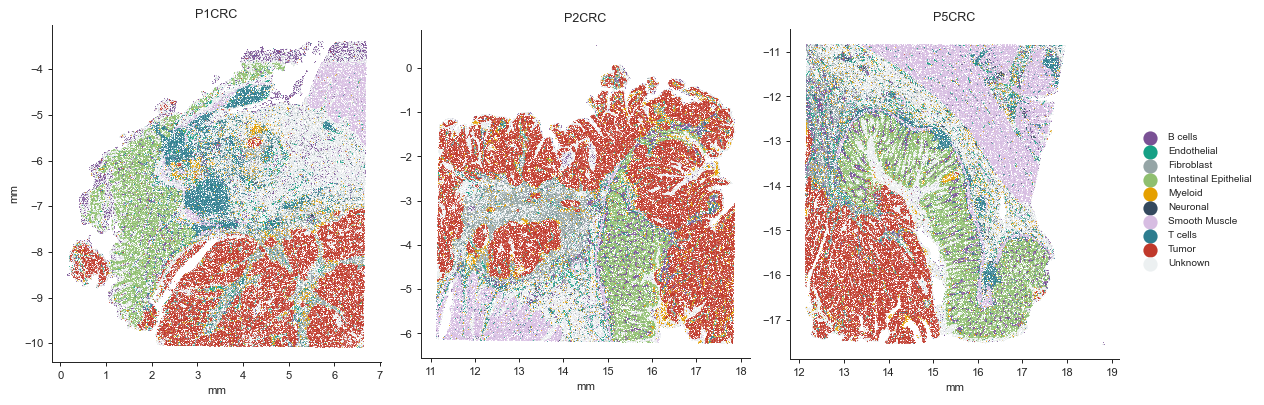

In [4]:
PAL = {"Tumor": "#c0392b", "T cells": "#2e7d8f", "B cells": "#7a5195",
       "Myeloid": "#e5a000", "Fibroblast": "#95a5a6", "Endothelial": "#16a085",
       "Intestinal Epithelial": "#8fbf6f", "Smooth Muscle": "#d7bde2",
       "Neuronal": "#34495e", "Unknown": "#ecf0f1"}

fig, axes = plt.subplots(1, len(secs), figsize=(4.2 * len(secs), 4.4))
for ax, (name, df) in zip(np.atleast_1d(axes), secs.items()):
    d = df.sample(min(120000, len(df)), random_state=SEED)
    for ct, g in d.groupby("UnsupervisedL1", observed=True):
        ax.scatter(g["x_um"] / 1000, g["y_um"] / 1000, s=.4, linewidths=0,
                   c=PAL.get(ct, "0.8"), label=ct, rasterized=True)
    ax.set_title(name, fontsize=10); ax.set_aspect("equal")
    ax.set_xlabel("mm"); sns.despine(ax=ax)
np.atleast_1d(axes)[0].set_ylabel("mm")
h, l = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(h, l, loc="center left", bbox_to_anchor=(1.0, .5), markerscale=18,
           fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "01_sections.png", bbox_inches="tight"); plt.show()

## 3. Distance from the tumour boundary

> ### Decision 2 — signed distance to the boundary, not distance to the nearest tumour bin
>
> - "Distance to the nearest tumour bin" is zero everywhere inside the tumour, which throws away the whole interior.
> - Instead: for a non-tumour bin, the distance to the nearest tumour bin, taken positive; for a tumour bin, the distance to the nearest non-tumour bin, taken negative.
> - That gives one continuous axis running from deep inside the tumour, through the edge at zero, out into the stroma.
> - Computed per section on its own coordinates. A tree is built once per section and queried both ways.

In [5]:
def signed_boundary_distance(df: pd.DataFrame, tumour_mask: np.ndarray) -> np.ndarray:
    xy = df[["x_um", "y_um"]].to_numpy(float)
    tum, non = xy[tumour_mask], xy[~tumour_mask]
    if len(tum) == 0 or len(non) == 0:
        return np.full(len(df), np.nan)
    d = np.empty(len(df))
    d[~tumour_mask] = cKDTree(tum).query(non, k=1)[0]        # outside: positive
    d[tumour_mask] = -cKDTree(non).query(tum, k=1)[0]        # inside: negative
    return d


for name, df in secs.items():
    is_tum = (df["UnsupervisedL1"] == "Tumor").to_numpy()
    df["dist_um"] = signed_boundary_distance(df, is_tum)
    df["section"] = name

pd.DataFrame({
    "tumour bins": {k: int((v["UnsupervisedL1"] == "Tumor").sum()) for k, v in secs.items()},
    "min (um)": {k: round(np.nanmin(v["dist_um"])) for k, v in secs.items()},
    "max (um)": {k: round(np.nanmax(v["dist_um"])) for k, v in secs.items()},
})

,tumour bins,min (um),max (um)
P1CRC,114101,-80,578
P2CRC,208299,-138,805
P5CRC,95624,-104,1748


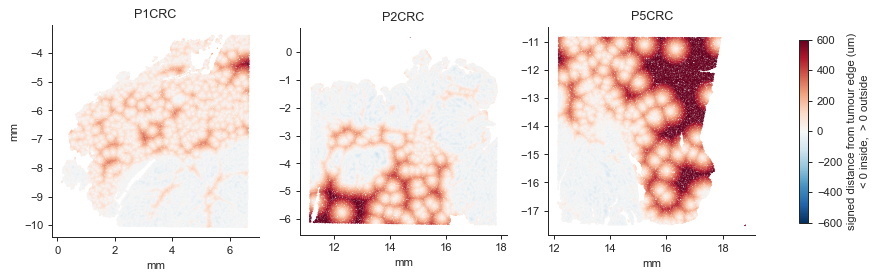

In [6]:
fig, axes = plt.subplots(1, len(secs), figsize=(4.2 * len(secs), 4.4))
for ax, (name, df) in zip(np.atleast_1d(axes), secs.items()):
    d = df.sample(min(120000, len(df)), random_state=SEED)
    v = np.clip(d["dist_um"], -600, 600)
    sc = ax.scatter(d["x_um"] / 1000, d["y_um"] / 1000, c=v, s=.4, linewidths=0,
                    cmap="RdBu_r", vmin=-600, vmax=600, rasterized=True)
    ax.set_title(name, fontsize=10); ax.set_aspect("equal"); ax.set_xlabel("mm")
    sns.despine(ax=ax)
np.atleast_1d(axes)[0].set_ylabel("mm")
fig.colorbar(sc, ax=np.atleast_1d(axes).tolist(), shrink=.6,
             label="signed distance from tumour edge (um)\n< 0 inside,  > 0 outside")
fig.savefig(FIGS / "02_distance.png", bbox_inches="tight"); plt.show()

## 4. Checking the distance against an independent label

> ### Decision 3 — validate a derived metric before building on it
>
> - The published metadata has its own `Periphery` column with a **50 micron** band around the tumour.
> - That band was drawn by the original authors, independently of anything computed here.
> - If the signed distance is right, bins labelled "50 micron" should sit just outside zero. If they do not, the boundary definition is wrong and everything downstream is too.

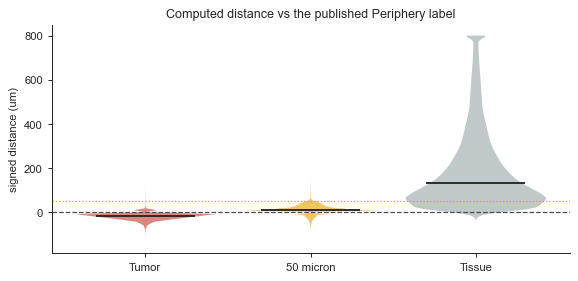

,count,25%,50%,75%
Periphery,,,,
50 micron,150926.0,8.0,11.3,24.0
Tissue,1022258.0,64.5,132.5,266.4
Tumor,422381.0,-28.8,-17.9,-8.0


In [7]:
chk = pd.concat([df[["section", "Periphery", "dist_um"]] for df in secs.values()])
chk = chk[chk["Periphery"].notna()]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
order = ["Tumor", "50 micron", "Tissue"]
cols = ["#c0392b", "#e5a000", "#95a5a6"]
data = [chk.loc[chk["Periphery"] == o, "dist_um"].clip(-800, 800).values for o in order]
parts = ax.violinplot(data, positions=range(len(order)), showextrema=False, widths=.85)
for b, c in zip(parts["bodies"], cols):
    b.set_facecolor(c); b.set_alpha(.6); b.set_edgecolor("none")
for i, d in enumerate(data):
    ax.hlines(np.median(d), i - .3, i + .3, color="0.15", lw=1.5, zorder=4)
ax.axhline(0, color="0.3", lw=1, ls="--")
ax.axhline(50, color="#e5a000", lw=1, ls=":")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("signed distance (um)")
ax.set_title("Computed distance vs the published Periphery label", fontsize=10)
sns.despine(ax=ax)
fig.tight_layout(); fig.savefig(FIGS / "03_validation.png", bbox_inches="tight"); plt.show()

chk.groupby("Periphery", observed=True)["dist_um"].describe()[["count", "25%", "50%", "75%"]].round(1)

## 5. Composition along the gradient

> ### Decision 4 — normalise inside each section before pooling
>
> - The sections differ in size, in how much tumour they contain, and in overall immune content.
> - Pooling raw bin counts would let the largest section set the shape of the curve.
> - So each section is binned by distance, composition is computed as a fraction **within that section and distance bin**, and only those fractions are pooled.
> - Distance bins narrower than ~25 µm are mostly empty at the extremes, so the axis is cut at ±600 µm where all three sections still contribute.

In [8]:
IMMUNE = ["T cells", "B cells", "Myeloid"]
EDGES = np.arange(-600, 625, 50)
CENTRES = (EDGES[:-1] + EDGES[1:]) / 2

rows = []
for name, df in secs.items():
    d = df[df["dist_um"].between(EDGES[0], EDGES[-1])].copy()
    d["bin"] = pd.cut(d["dist_um"], EDGES, labels=CENTRES)
    tot = d.groupby("bin", observed=True).size().rename("n_total")
    for ct in IMMUNE:
        n = d[d["UnsupervisedL1"] == ct].groupby("bin", observed=True).size().rename("n")
        g = pd.concat([n, tot], axis=1).fillna(0)
        g = g[g["n_total"] >= 200]                 # drop sparsely covered bins
        rows.append(pd.DataFrame({"section": name, "celltype": ct,
                                  "dist_um": g.index.astype(float),
                                  "frac": g["n"] / g["n_total"],
                                  "n_total": g["n_total"].values}))
prof = pd.concat(rows, ignore_index=True)
print(f"{len(prof)} section x celltype x distance-bin observations")
prof.head()

123 section x celltype x distance-bin observations


,section,celltype,dist_um,frac,n_total
0,P1CRC,T cells,25.0,0.056654,143061
1,P1CRC,T cells,75.0,0.093151,121083
2,P1CRC,T cells,125.0,0.146220,70900
3,P1CRC,T cells,175.0,0.235217,32183
4,P1CRC,T cells,225.0,0.299974,15218


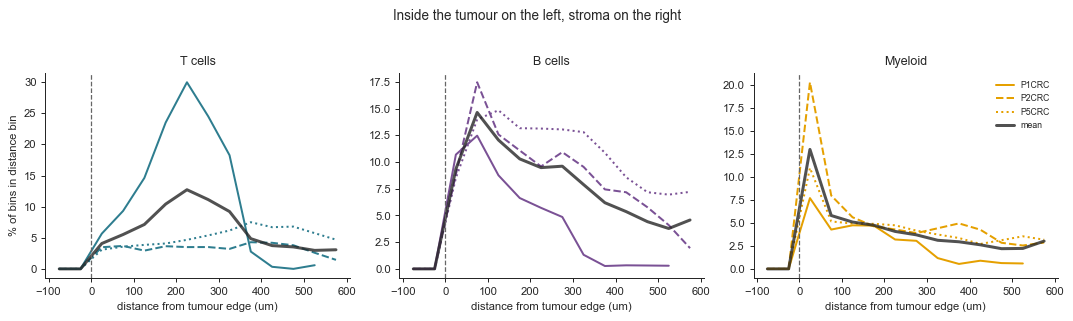

In [9]:
fig, axes = plt.subplots(1, len(IMMUNE), figsize=(4.0 * len(IMMUNE), 3.4), sharex=True)
secnames = list(secs)
lines = ["-", "--", ":"]
for ax, ct in zip(axes, IMMUNE):
    for ls, name in zip(lines, secnames):
        d = prof[(prof["celltype"] == ct) & (prof["section"] == name)].sort_values("dist_um")
        ax.plot(d["dist_um"], 100 * d["frac"], ls, color=PAL[ct], lw=1.6, label=name)
    m = (prof[prof["celltype"] == ct].groupby("dist_um", observed=True)["frac"].mean() * 100)
    ax.plot(m.index, m.values, color="0.15", lw=2.4, alpha=.8, label="mean")
    ax.axvline(0, color="0.4", lw=1, ls="--")
    ax.set_title(ct, fontsize=10); ax.set_xlabel("distance from tumour edge (um)")
    sns.despine(ax=ax)
axes[0].set_ylabel("% of bins in distance bin")
axes[-1].legend(fontsize=7, frameon=False)
fig.suptitle("Inside the tumour on the left, stroma on the right", y=1.03)
fig.tight_layout(); fig.savefig(FIGS / "04_gradient.png", bbox_inches="tight"); plt.show()

## 6. Does the gradient replicate?

> ### Decision 5 — require consistency across sections, not a pooled p-value
>
> - With ~500,000 bins per section, any test run on pooled bins returns a vanishing p-value. Bins within a section are not independent observations of anything.
> - The question is whether the *direction* of the gradient is the same in each section.
> - So each section is fitted separately — Spearman correlation between distance and immune fraction — and the result is only reported if the sign agrees in at least 2 of 3.

In [10]:
rows = []
for ct in IMMUNE:
    for name in secs:
        d = prof[(prof["celltype"] == ct) & (prof["section"] == name)]
        if len(d) < 8: continue
        rho, p = stats.spearmanr(d["dist_um"], d["frac"])
        rows.append({"celltype": ct, "section": name, "rho": round(rho, 3), "p": p})
per_sec = pd.DataFrame(rows)

summary = (per_sec.groupby("celltype", observed=True)
           .agg(sections=("section", "count"),
                mean_rho=("rho", "mean"),
                same_sign=("rho", lambda s: int(max((s > 0).sum(), (s < 0).sum()))))
           .round(3))
summary["direction"] = np.where(summary["mean_rho"] > 0, "rises away from tumour", "falls away from tumour")
summary["replicates"] = summary["same_sign"].astype(str) + "/" + summary["sections"].astype(str)
print(per_sec.to_string(index=False))
print()
summary[["mean_rho", "direction", "replicates"]]

celltype section    rho        p
 T cells   P1CRC  0.017 0.957140
 T cells   P2CRC  0.308 0.283981
 T cells   P5CRC  0.849 0.000121
 B cells   P1CRC -0.173 0.571227
 B cells   P2CRC -0.163 0.578116
 B cells   P5CRC -0.084 0.776284
 Myeloid   P1CRC -0.162 0.596258
 Myeloid   P2CRC -0.176 0.547224
 Myeloid   P5CRC -0.207 0.478056



,mean_rho,direction,replicates
celltype,,,
B cells,-0.140,falls away from tumour,3/3
Myeloid,-0.182,falls away from tumour,3/3
T cells,0.391,rises away from tumour,3/3


## 7. Expression along the same axis

The count matrix is needed for this part, so it is shown for one section.
The point is that the axis built from the annotation can be applied directly to
expression without any further modelling.

In [11]:
import scanpy as sc

h5 = sections.loc[sections["counts"].notna() & (sections["counts"] != ""), :]
sec_name = h5.iloc[0]["section"]
ad = sc.read_10x_h5(DATA / h5.iloc[0]["counts"])
ad.var_names_make_unique()

meta = secs[sec_name].set_index("barcode")
shared = ad.obs_names.intersection(meta.index)
ad = ad[shared].copy()
ad.obs["dist_um"] = meta.loc[shared, "dist_um"].values
ad.obs["celltype"] = meta.loc[shared, "UnsupervisedL1"].values
print(f"{sec_name}: {ad.n_obs} bins matched to the metadata, {ad.n_vars} genes")

sc.pp.filter_genes(ad, min_cells=50)
sc.pp.normalize_total(ad, target_sum=1e4)
sc.pp.log1p(ad)

P1CRC: 507684 bins matched to the metadata, 18085 genes


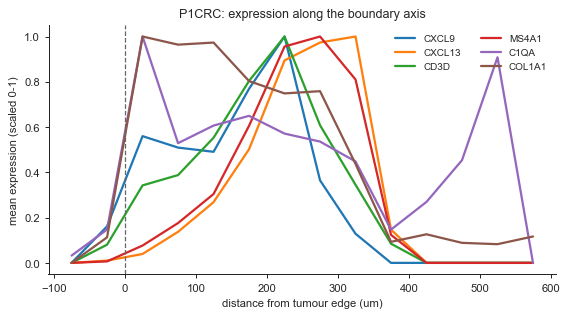

In [12]:
GENES = ["CXCL9", "CXCL13", "CD3D", "MS4A1", "C1QA", "COL1A1"]
genes = [g for g in GENES if g in ad.var_names]

d = ad.obs["dist_um"].to_numpy()
keep = np.abs(d) <= 600
bins = pd.cut(d[keep], EDGES, labels=CENTRES)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for g in genes:
    x = np.asarray(ad[keep, g].X.todense()).ravel()
    m = pd.Series(x).groupby(bins, observed=True).mean()
    m = (m - m.min()) / (m.max() - m.min() + 1e-9)
    ax.plot(m.index.astype(float), m.values, lw=1.8, label=g)
ax.axvline(0, color="0.4", lw=1, ls="--")
ax.set_xlabel("distance from tumour edge (um)")
ax.set_ylabel("mean expression (scaled 0-1)")
ax.set_title(f"{sec_name}: expression along the boundary axis", fontsize=10)
ax.legend(fontsize=8, frameon=False, ncol=2)
sns.despine(ax=ax)
fig.tight_layout(); fig.savefig(FIGS / "05_expression_gradient.png", bbox_inches="tight"); plt.show()

## 8. Results

**Method**

- The coordinate scale was measured from the bin lattice rather than assumed, and came out consistent across all three sections at a 6.5 mm capture area.
- The boundary axis is a signed distance, so it covers the tumour interior as well as the stroma.
- It was checked against the authors' own `Periphery` annotation before anything was built on it.
- Composition was normalised within section and distance bin, then pooled — no section dominates the curve.
- Gradients are reported by direction and replication across sections, not by a p-value computed over half a million non-independent bins.

**Limitations**

- Three sections from three patients. Direction can replicate; effect size cannot be estimated with any precision.
- The cell-type calls are the published per-bin annotation, not re-derived here. At 8 µm a bin is not guaranteed to be one cell, so these are bin-level compositions rather than cell counts.
- The boundary is defined from the annotation's tumour call. A section with fragmented tumour will produce a noisier axis than one with a single front.
- The expression panel is one section, and no spatially-aware model was fitted — the curves are descriptive.

### Reproducing

```
bash 00_download_data.sh
conda env create -f environment.yml
conda activate spatial-demo
jupyter lab crc_border_transition.ipynb
```